In [1]:
# importar módulos

import pandas as pd # fw para manejo de datos (r studio)
import numpy as np # fw para manejo de colecciones / arrays en bajo nivel
import matplotlib.pyplot as plt # fw para graficar
import seaborn as sns # fw para visualizar estadisticas

In [2]:
# Cargas Datos de dataset
# fuente: Kaggle: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database?resource=download

diabetes = pd.read_csv('diabetes-pima.csv')
print(diabetes.shape)

(768, 9)


In [5]:
#print(diabetes)
diabetes.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [8]:
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
diabetes.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

/Users/joelsebastiantorrescarrasco/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


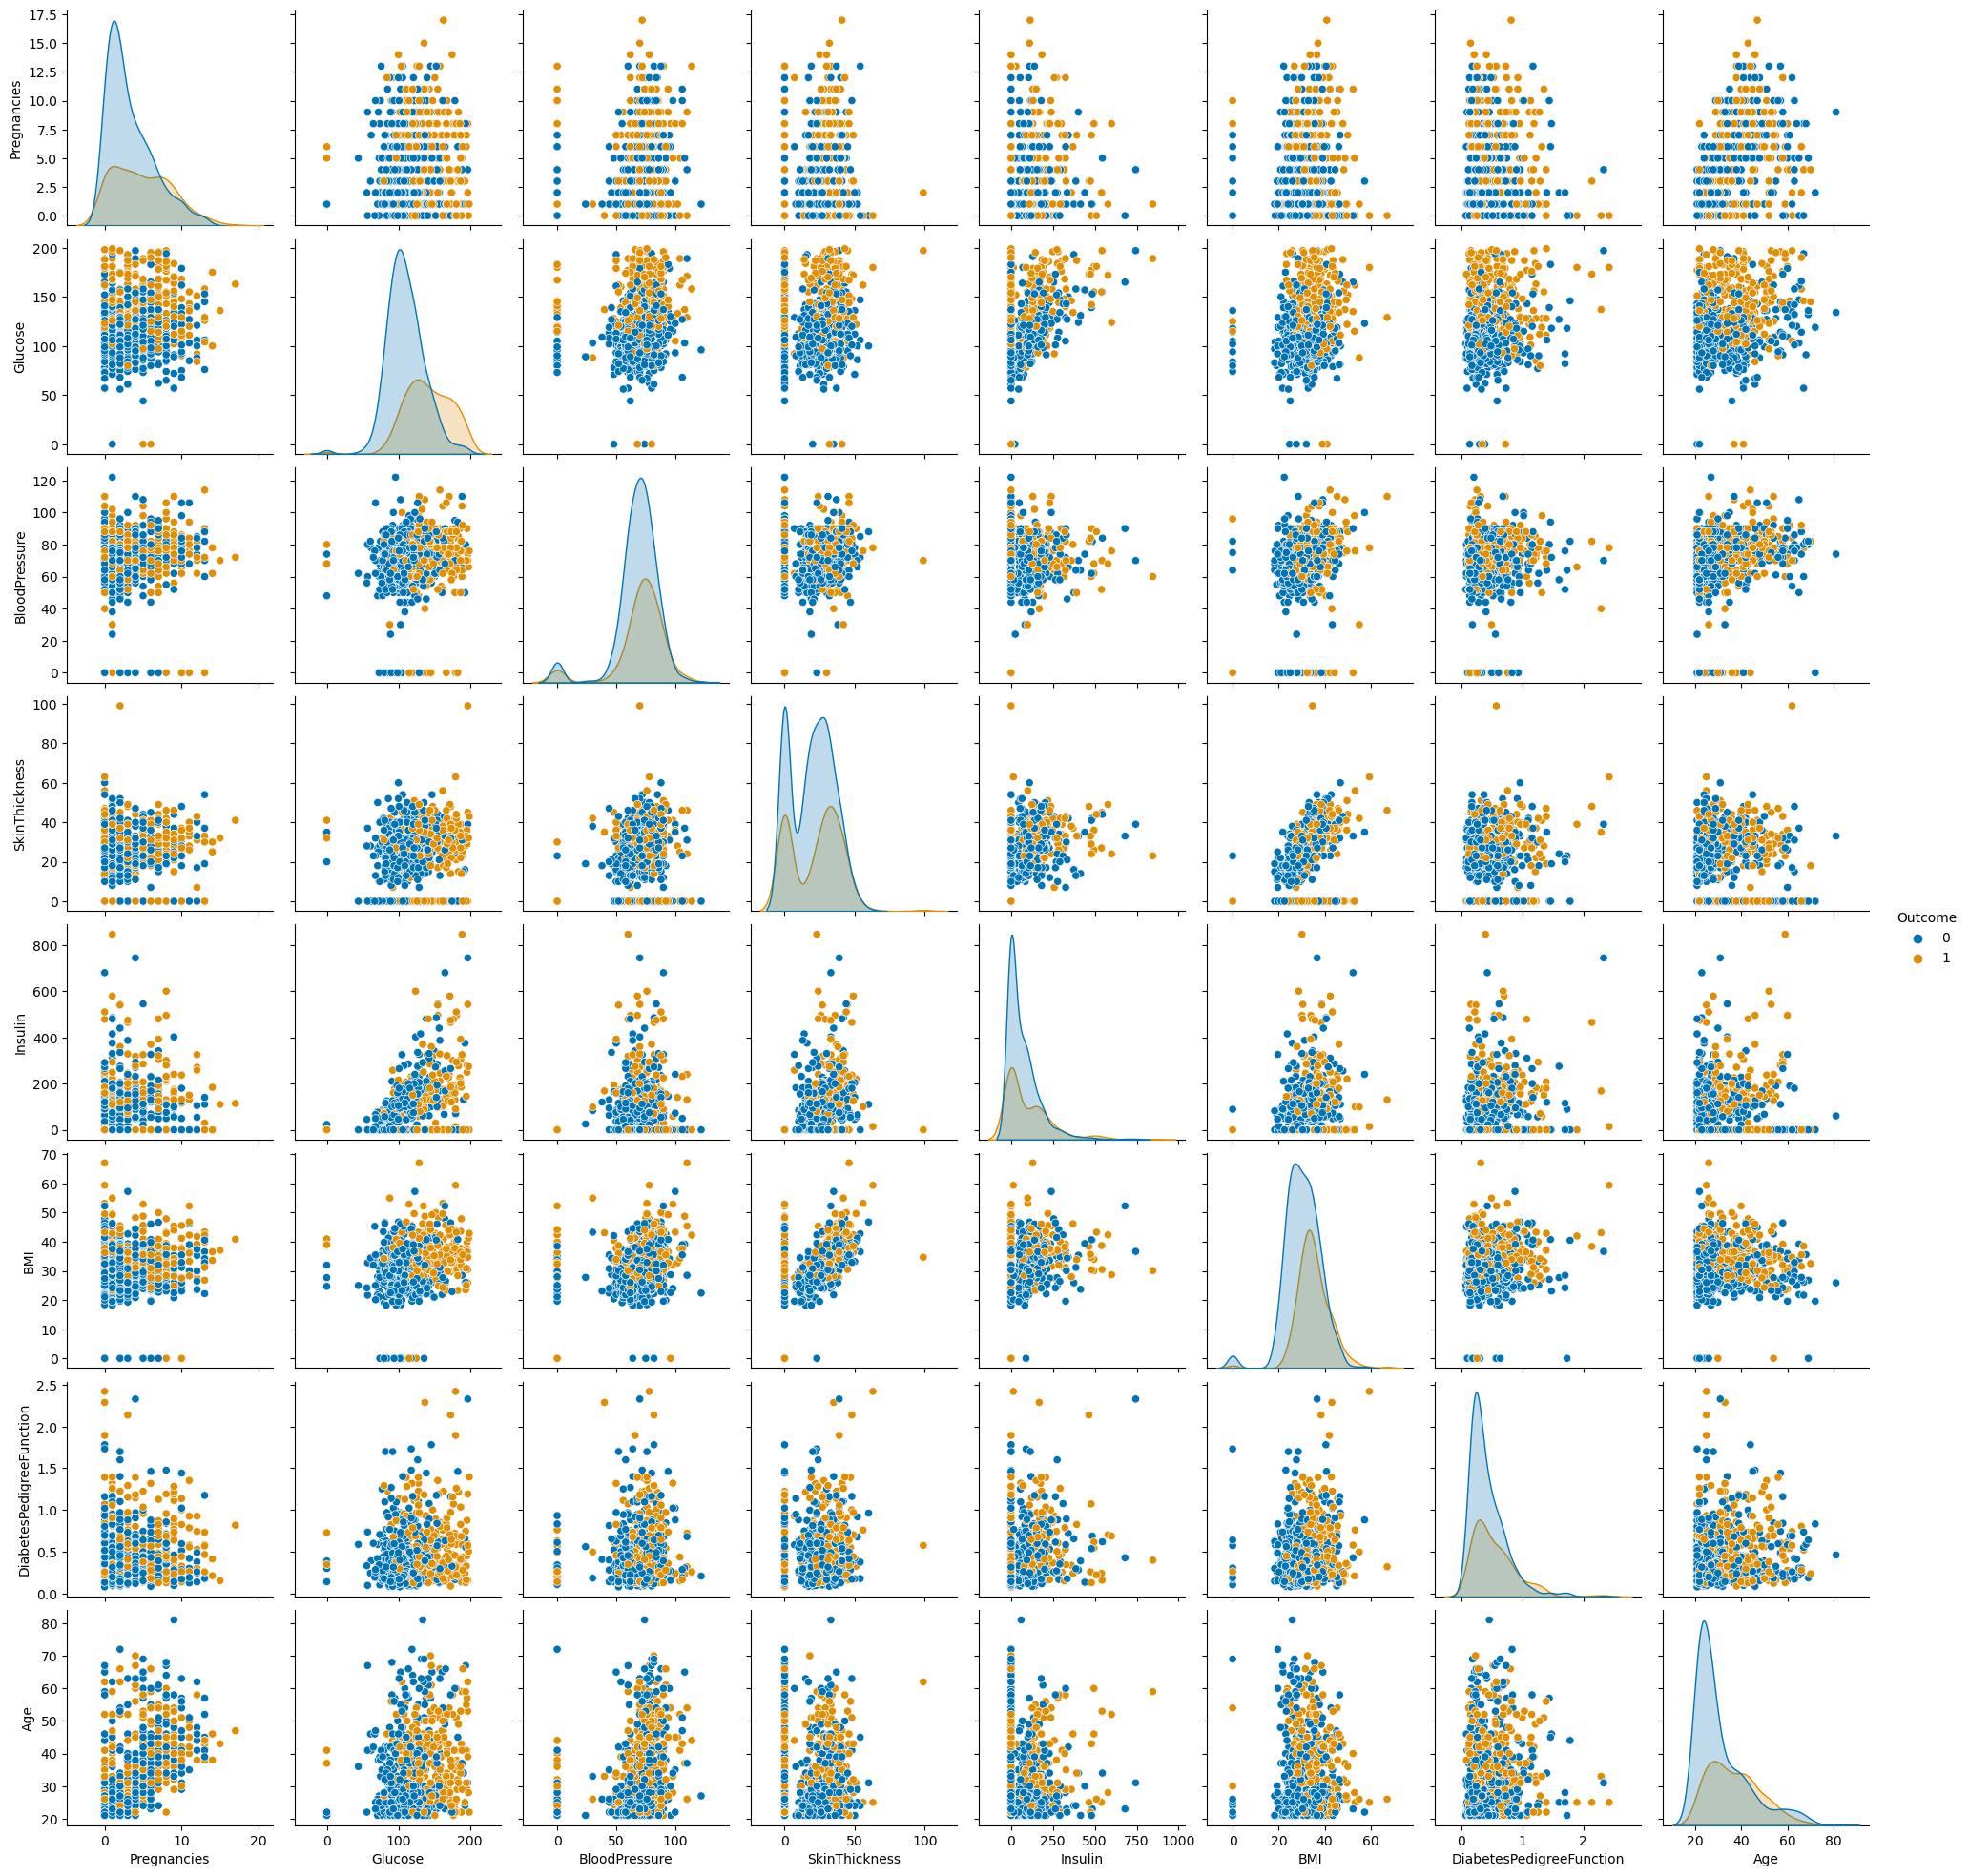

In [7]:
#Graficar cada variable y entender su correspondencia
sns.pairplot(diabetes, hue="Outcome", palette= "colorblind");

In [3]:
#Preprocesamiento del conjunto de dato para entrenamiento
X = diabetes.drop("Outcome", axis = 1).values
y = diabetes["Outcome"].values

print(f"Conjunto X tamaño: {X.shape}")
print(f"Conjunto y tamaño: {y.shape}")

Conjunto X tamaño: (768, 8)
Conjunto y tamaño: (768,)


In [4]:
# Separación para Conjuntos de entrenamiento y testeo
from sklearn.model_selection import train_test_split

X_e, X_t, y_e, y_t = train_test_split(X, y, test_size=0.3, stratify = diabetes['Outcome'], random_state = 40)
print(f"X_e: {X_e.shape} - y_e: {y_e.shape}")
print(f"X_t: {X_t.shape} - y_t: {y_t.shape}")

X_e: (537, 8) - y_e: (537,)
X_t: (231, 8) - y_t: (231,)


# Crear modelo con Sklearn

In [31]:
from sklearn.neural_network import MLPClassifier

rn_skl = MLPClassifier(hidden_layer_sizes = (8,8,4,1), activation = 'logistic', solver='lbfgs', max_iter = 1000)
rn_skl

MLPClassifier(activation='logistic', hidden_layer_sizes=(8, 8, 4, 1),
              max_iter=1000, solver='lbfgs')

In [32]:
#Entrenamiento
rn_skl.fit(X_e, y_e)

/Users/joelsebastiantorrescarrasco/anaconda3/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


MLPClassifier(activation='logistic', hidden_layer_sizes=(8, 8, 4, 1),
              max_iter=1000, solver='lbfgs')

In [33]:
#evaluar el modelo
from sklearn.metrics import classification_report, confusion_matrix

valores_entrenamiento = rn_skl.predict(X_e)
valores_testeo = rn_skl.predict(X_t)

print("Rendimiento Entrenamiento")
print(f"Matrix de Confusion \n{confusion_matrix(y_e, valores_entrenamiento)}")
print(f"Reporte de Clasificacion \n{classification_report(y_e, valores_entrenamiento)}")

Rendimiento Entrenamiento
Matrix de Confusion 
[[281  69]
 [106  81]]
Reporte de Clasificacion 
              precision    recall  f1-score   support

           0       0.73      0.80      0.76       350
           1       0.54      0.43      0.48       187

    accuracy                           0.67       537
   macro avg       0.63      0.62      0.62       537
weighted avg       0.66      0.67      0.66       537



# Crear modelo con PyTorch

In [5]:
# importar modulos de pytoch
import torch
import torch.nn as nn
import torch.nn.functional as F

In [6]:
# Preprocesamiento para trabajar con torch
# transformar desde valores nominales a arreglos de tensores

X_e_t = torch.FloatTensor(X_e)
X_t_t = torch.FloatTensor(X_t)

y_e_t = torch.LongTensor(y_e)
y_t_t = torch.LongTensor(y_t)

In [54]:
print(y_e)

[0 0 0 0 0 1 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 0 0 1 1 1 0 0 1 0 0 0 1 0 0 0 0
 0 1 0 0 1 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 1 1 0 0 1 0 0 0
 0 0 1 0 0 0 0 0 1 0 1 0 1 1 0 1 1 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0
 0 0 1 1 0 0 1 1 1 0 0 0 1 0 0 0 0 0 0 0 1 1 1 1 1 0 0 0 1 1 1 1 0 0 0 0 0
 1 0 1 0 1 1 0 0 1 1 1 0 0 0 0 0 1 0 0 1 1 0 0 0 1 1 0 0 0 0 0 0 0 1 0 0 1
 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0
 1 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 0 0 1 1 0 1 0 1 1 1 0 1 0 0 0 0 0 1 0 1 0
 0 0 0 1 0 1 0 0 0 1 1 0 1 1 1 0 1 0 0 0 1 0 0 0 1 1 0 1 0 1 1 0 0 0 0 1 0
 1 0 0 0 1 0 0 0 0 1 0 1 1 0 0 1 0 1 1 0 0 0 0 1 0 0 1 0 0 1 0 0 1 0 0 0 1
 0 0 1 1 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 0 1 1 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0
 0 1 1 1 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 1 1 1 1 0 0 0 0 1 0 0 0 1 1 1 1 1 1
 0 0 1 0 1 1 0 1 0 0 0 1 0 0 0 0 0 1 1 1 0 0 0 1 0 1 0 0 0 0 0 1 1 0 0 0 0
 0 0 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 1 0 0 1 1 0 1 0 1 1 0 1 0 0 0 0 1 0 1
 1 0 1 1 1 0 1 0 1 0 0 1 

In [55]:
print(y_e_t)

tensor([0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1,
        1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0,
        0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1,
        0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1,
        0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0,
        0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1,
        1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
        1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0,
        1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0,
        1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0,
        1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0,

In [7]:
# crear la arquitectura del modelo
class Arquitectura(nn.Module):
    def __init__(self, input_features = 8, hidden1 = 2, out_features = 2):
        super().__init__()
        # definir las conexiones
        # unir input_features > hidden1 > out_features
        self.f_connected1 = nn.Linear(input_features, hidden1)
        self.f_connected2 = nn.Linear(hidden1, out_features)
        # en las conexiones se realiza la instrucción de la suma ponderada
    
    def forward(self, x):
        # las transformaciones dentro de las neuronas con las funciones de activacion
        x = F.logsigmoid(self.f_connected1(x))
        x = F.logsigmoid(self.f_connected2(x))
        return x

In [8]:
# Crear la instancia del modelo
torch.manual_seed(40)
rn_torch = Arquitectura()
rn_torch.parameters
rn_torch.parameters()

<generator object Module.parameters at 0x16480cc80>

In [102]:
print(X_e_t.shape)
print(y_e_t.shape)
print(y_e_t[0])

torch.Size([537, 8])
torch.Size([537])
tensor(0)


In [89]:
# Crear Entrenamiento basado en Backpropagation
costo = nn.CrossEntropyLoss()
optimizador = torch.optim.LBFGS(rn_torch.parameters(), lr = 0.001)
epochs = 1000
costos_totales = []

# Comienza el entrenamiento basado en backpropagation
for i in range(epochs):
    #Forward
    y_p = rn_torch.forward(X_e_t)
    print(y_p.shape)    
    print(y_p[0])    
    print(y_p[1])    
    c = costo(y_p, y_e_t) # perdida del valor real vs el valor predicho
    costos_totales.append(c)
    
    if i%10 == 1:
        print('Generación: {} con costo: {}'.format(i, c.item()))
    
    optimizador.zero_grad()
    c.backward() #transfiere el costo hacia atrás, cada neurona en cada capa tiene su costo asociado
    optimizador.step() #Ajuste en cada neurona

torch.Size([537, 2])
tensor([-3.5268e-08, -2.1360e-06], grad_fn=<SelectBackward0>)
tensor([-0.2679, -0.3088], grad_fn=<SelectBackward0>)


NameError: name 'closure' is not defined

In [9]:
# Crear Entrenamiento basado en Backpropagation
costo = nn.CrossEntropyLoss()
optimizador = torch.optim.LBFGS(rn_torch.parameters(), lr = 0.001)
epochs = 1000
costos_totales = []

# Comienza el entrenamiento basado en backpropagation
for i in range(epochs):
    #Forward
    def closure():
        y_p = rn_torch.forward(X_e_t) 
        c = costo(y_p, y_e_t) # perdida del valor real vs el valor predicho
        costos_totales.append(c)

        if i%10 == 1:
            print('Generación: {} con costo: {}'.format(i, c.item()))

        optimizador.zero_grad()
        c.backward() #transfiere el costo hacia atrás, cada neurona en cada capa tiene su costo asociado
        return c
    optimizador.step(closure) #Ajuste en cada neurona

Generación: 1 con costo: 0.7135460376739502
Generación: 1 con costo: 0.7133277058601379
Generación: 1 con costo: 0.7131215333938599
Generación: 1 con costo: 0.7129256129264832
Generación: 1 con costo: 0.7127383351325989
Generación: 1 con costo: 0.7125580310821533
Generación: 1 con costo: 0.7123838067054749
Generación: 1 con costo: 0.7122142314910889
Generación: 1 con costo: 0.7120486497879028
Generación: 1 con costo: 0.7118858098983765
Generación: 1 con costo: 0.7117250561714172
Generación: 1 con costo: 0.7115651369094849
Generación: 1 con costo: 0.7114053964614868
Generación: 1 con costo: 0.711244523525238
Generación: 1 con costo: 0.7110814452171326
Generación: 1 con costo: 0.7109145522117615
Generación: 1 con costo: 0.7107419967651367
Generación: 1 con costo: 0.7105615139007568
Generación: 1 con costo: 0.7103692889213562
Generación: 1 con costo: 0.7101600170135498
Generación: 11 con costo: 0.6817788481712341
Generación: 11 con costo: 0.6814920902252197
Generación: 11 con costo: 0.681

In [24]:
costos_totales_n = [] 
for c in costos_totales:
    costos_totales_n.append(c.detach().numpy().item())

In [45]:
costos_totales_m = costos_totales_n[:1000]
print(len(costos_totales_m))
print(costos_totales_m)

1000
[0.7178767919540405, 0.71773761510849, 0.71771639585495, 0.7176879644393921, 0.7176512479782104, 0.7176041007041931, 0.7175433039665222, 0.7174637317657471, 0.717357337474823, 0.7172114253044128, 0.7170069217681885, 0.7167181968688965, 0.7163242697715759, 0.7158477306365967, 0.7153732180595398, 0.7149614691734314, 0.7146115899085999, 0.7143058776855469, 0.7140310406684875, 0.7137793898582458, 0.7135460376739502, 0.7133277058601379, 0.7131215333938599, 0.7129256129264832, 0.7127383351325989, 0.7125580310821533, 0.7123838067054749, 0.7122142314910889, 0.7120486497879028, 0.7118858098983765, 0.7117250561714172, 0.7115651369094849, 0.7114053964614868, 0.711244523525238, 0.7110814452171326, 0.7109145522117615, 0.7107419967651367, 0.7105615139007568, 0.7103692889213562, 0.7101600170135498, 0.7099236845970154, 0.7096414566040039, 0.7092624306678772, 0.7085329294204712, 0.7078020572662354, 0.7070674896240234, 0.706328809261322, 0.7055882811546326, 0.704784095287323, 0.7046584486961365, 0.

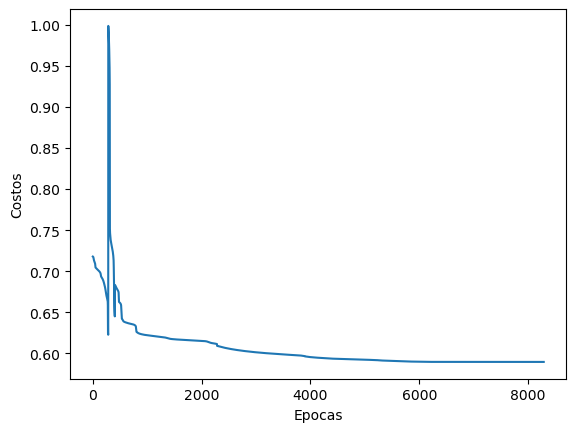

In [48]:
# Visualización del Modelo
plt.plot(range(8287), costos_totales_n)
plt.ylabel('Costos')
plt.xlabel('Epocas')
plt.show()

In [49]:
#Evaluación de las predicciones

predicciones_train = []

with torch.no_grad():
    for i, data in enumerate(X_e_t):
        y_p = rn_torch(data)
        predicciones_train.append(y_p.argmax().item())
print(predicciones_train)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 

In [52]:
from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_e_t, predicciones_train))
print(classification_report(y_e_t, predicciones_train))

[[340  10]
 [163  24]]
              precision    recall  f1-score   support

           0       0.68      0.97      0.80       350
           1       0.71      0.13      0.22       187

    accuracy                           0.68       537
   macro avg       0.69      0.55      0.51       537
weighted avg       0.69      0.68      0.60       537



In [56]:
#Evaluación de las predicciones

predicciones_test = []

with torch.no_grad():
    for i, data in enumerate(X_t_t):
        y_p = rn_torch(data)
        predicciones_test.append(y_p.argmax().item())
print(predicciones_test)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0]


In [57]:
print(confusion_matrix(y_t_t, predicciones_test))
print(classification_report(y_t_t, predicciones_test))

[[144   6]
 [ 76   5]]
              precision    recall  f1-score   support

           0       0.65      0.96      0.78       150
           1       0.45      0.06      0.11        81

    accuracy                           0.65       231
   macro avg       0.55      0.51      0.44       231
weighted avg       0.58      0.65      0.54       231



# Implementación con Keras/Tensorflow

In [81]:

!pip install keras

In [82]:
!pip install tensorflow

  Obtaining dependency information for keras>=3.0.0 from https://files.pythonhosted.org/packages/8d/44/c604ecc5c9993b6574a681f2f505e980725871a89cfd9e48597b12ccb506/keras-3.3.3-py3-none-any.whl.metadata
  Using cached keras-3.3.3-py3-none-any.whl.metadata (5.7 kB)
Using cached keras-3.3.3-py3-none-any.whl (1.1 MB)
  Attempting uninstall: keras
    Found existing installation: Keras 2.2.4
    Uninstalling Keras-2.2.4:
      Successfully uninstalled Keras-2.2.4


In [5]:
from keras.models import Sequential
from keras.layers import Dense

In [31]:
#Diseño del Modelo 
rn_keras = Sequential()
rn_keras.add(Dense(8, input_dim=8, activation='linear'))
rn_keras.add(Dense(32, activation='relu6'))
rn_keras.add(Dense(32, activation='relu6'))
rn_keras.add(Dense(32, activation='relu6'))
rn_keras.add(Dense(8, activation = 'relu6'))
rn_keras.add(Dense(4, activation = 'relu6'))
rn_keras.add(Dense(1, activation = 'tanh'))

# Completar o sellar el modelo
# determinar hiperparámetros
rn_keras.compile(loss="binary_crossentropy", optimizer="adam", metrics=['accuracy'])

In [32]:
#Entrenamiento
# El método .fit es el que realiza el entrenamiento del modelo

historial = rn_keras.fit(X_e, y_e, epochs = 1000, batch_size=10, validation_data = (X_t, y_t))

Epoch 1/1000
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5629 - loss: 0.7925 - val_accuracy: 0.6320 - val_loss: 0.6498
Epoch 2/1000
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 765us/step - accuracy: 0.6646 - loss: 0.6270 - val_accuracy: 0.6494 - val_loss: 0.6375
Epoch 3/1000
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 719us/step - accuracy: 0.6997 - loss: 0.6185 - val_accuracy: 0.6710 - val_loss: 0.6571
Epoch 4/1000
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 634us/step - accuracy: 0.6585 - loss: 0.6024 - val_accuracy: 0.6494 - val_loss: 0.6624
Epoch 5/1000
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 662us/step - accuracy: 0.7392 - loss: 0.5350 - val_accuracy: 0.6580 - val_loss: 0.6662
Epoch 6/1000
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 729us/step - accuracy: 0.7013 - loss: 0.5295 - val_accuracy: 0.5801 - val_loss: 0.6899
Epoch 7/1000
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 891us/step - accuracy: 0.7201 - loss: 0.5558 - val_accuracy: 0.6494 - val_loss: 0.6821
Epoch 8/1000
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6836 - loss: 0.5545 - val_

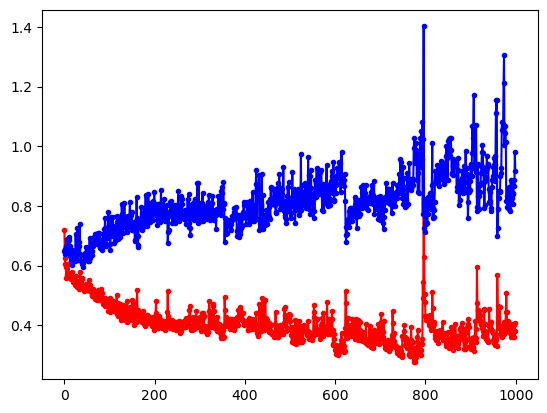

In [33]:
# Graficar la pérdida de la evolución del entrenamiento
plt.plot(historial.history["loss"], 'r', marker='.', label = 'Train Loss')
plt.plot(historial.history["val_loss"], 'b', marker='.', label = 'Validation Loss')
plt.show();

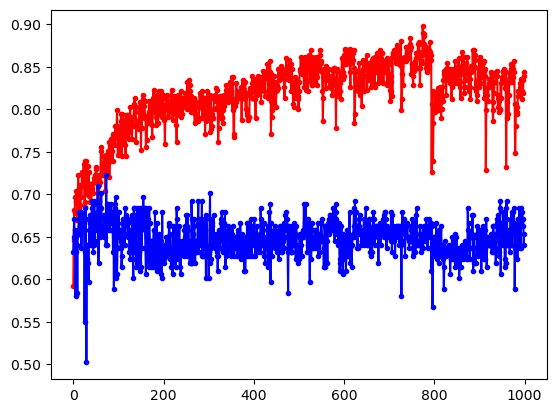

In [34]:
# Graficar la pérdida de la evolución del entrenamiento
plt.plot(historial.history["accuracy"], 'r', marker='.', label = 'Train Accuracy')
plt.plot(historial.history["val_accuracy"], 'b', marker='.', label = 'Validation Accuracy')
plt.show();

In [38]:
#Evaluación Entrenamiento
evaluacion = rn_keras.evaluate(X_e, y_e)

print("\nn%s: %.2f%%" % (rn_keras.metrics_names[1], evaluacion[1]*100))

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 460us/step - accuracy: 0.7435 - loss: 0.4963

ncompile_metrics: 71.88%


In [39]:
#Evaluación Entrenamiento
evaluacion = rn_keras.evaluate(X_t, y_t)

print("\nn%s: %.2f%%" % (rn_keras.metrics_names[1], evaluacion[1]*100))

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 544us/step - accuracy: 0.6395 - loss: 0.6485

ncompile_metrics: 63.20%


In [40]:
#predicciones
from sklearn.metrics import classification_report, confusion_matrix

y_p = rn_keras.predict(X_e)
y_p = np.argmax(y_p, axis=1)

print(confusion_matrix(y_e, y_p))
print(classification_report(y_e, y_p))

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
[[350   0]
 [187   0]]
              precision    recall  f1-score   support

           0       0.65      1.00      0.79       350
           1       0.00      0.00      0.00       187

    accuracy                           0.65       537
   macro avg       0.33      0.50      0.39       537
weighted avg       0.42      0.65      0.51       537



/Users/joelsebastiantorrescarrasco/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/joelsebastiantorrescarrasco/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/joelsebastiantorrescarrasco/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(avera

In [41]:
# Predicciones de testeo
y_p = rn_keras.predict(X_t)
y_p = np.argmax(y_p, axis=1)

print(confusion_matrix(y_t, y_p))
print(classification_report(y_t, y_p))

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 543us/step
[[150   0]
 [ 81   0]]
              precision    recall  f1-score   support

           0       0.65      1.00      0.79       150
           1       0.00      0.00      0.00        81

    accuracy                           0.65       231
   macro avg       0.32      0.50      0.39       231
weighted avg       0.42      0.65      0.51       231



/Users/joelsebastiantorrescarrasco/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/joelsebastiantorrescarrasco/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/joelsebastiantorrescarrasco/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(avera